In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")


## load datsets

In [2]:
DATA_DIR = Path("../data/raw")

dataframes = {}

for year in range(2017, 2026):
    file_path = DATA_DIR / f"gpg_{year}.csv"

    df = pd.read_csv(file_path)

    dataframes[year] = df

    print(year, df.shape)

2017 (10569, 27)
2018 (10838, 27)
2019 (7055, 27)
2020 (10583, 27)
2021 (10567, 27)
2022 (10908, 27)
2023 (11169, 27)
2024 (11315, 27)
2025 (11201, 27)


##  combine datasets

In [3]:
all_data = []

for year, df in dataframes.items():
    df = df.copy()
    df["report_year"] = year
    all_data.append(df)

data = pd.concat(all_data, ignore_index=True)

print("Dataset shape:", data.shape)
data.head()

Dataset shape: (94205, 28)


,EmployerName,EmployerId,Address,PostCode,CompanyNumber,SicCodes,DiffMeanHourlyPercent,DiffMedianHourlyPercent,DiffMeanBonusPercent,DiffMedianBonusPercent,MaleBonusPercent,FemaleBonusPercent,MaleLowerQuartile,FemaleLowerQuartile,MaleLowerMiddleQuartile,FemaleLowerMiddleQuartile,MaleUpperMiddleQuartile,FemaleUpperMiddleQuartile,MaleTopQuartile,FemaleTopQuartile,CompanyLinkToGPGInfo,ResponsiblePerson,EmployerSize,CurrentName,SubmittedAfterTheDeadline,DueDate,DateSubmitted,report_year
0,"""Bryanston School"",Incorporated",676,"Bryanston House, Blandford, Dorset, DT11 0PX",DT11 0PX,00226143,85310,18.0,28.2,0.0,0.0,0.0,0.0,24.4,75.6,50.8,49.2,49.2,50.8,51.5,48.5,https://www.bryanston.co.uk/employment,Nick McRobb (Bursar and Clerk to the Governors),500 to 999,BRYANSTON SCHOOL,False,2018/04/05 00:00:00,2018/03/27 11:42:49,2017
1,"""RED BAND"" CHEMICAL COMPANY, LIMITED",16879,"19 Smith's Place, Leith Walk, Edinburgh, EH6 8NU",EH6 8NU,SC016876,47730,2.3,-2.7,15.0,37.5,15.6,66.7,20.3,79.7,25.4,74.6,10.3,89.7,18.1,81.9,NaN,Philip Galt (Managing Director),250 to 499,"""RED BAND"" CHEMICAL COMPANY, LIMITED",False,2018/04/05 00:00:00,2018/03/28 16:44:25,2017
2,118 LIMITED,681,"5th Floor, 1 Capital Quarter, Tyndall Street, ...",CF10 4BZ,03951948,61900,1.7,2.8,13.1,13.6,70.0,57.0,51.0,49.0,53.0,47.0,50.0,50.0,58.0,42.0,NaN,"Emma Crowe (VP, Human Resources)",500 to 999,118 LIMITED,False,2018/04/05 00:00:00,2018/03/27 19:10:41,2017
3,123 EMPLOYEES LTD,17677,"Alexandra Dock Business Centre, Fishermans Wha...",DN31 1UL,10530651,78300,41.0,36.0,-69.8,-157.2,50.0,73.5,0.0,100.0,2.0,98.0,11.0,89.0,23.0,77.0,NaN,Chloe Lines (Financial Controller),250 to 499,123 EMPLOYEES LTD,True,2018/04/05 00:00:00,2018/05/04 11:24:06,2017
4,1610 LIMITED,682,"Trinity Sports And Leisure, Chilton Street, Br...",TA6 3JA,06727055,93110,-22.0,-34.0,-47.0,-67.0,25.0,75.0,56.0,44.0,52.0,48.0,30.0,70.0,24.0,76.0,https://www.1610.org.uk/gender-pay-gap/,Tim Nightingale (CEO),250 to 499,1610 LIMITED,True,2018/04/05 00:00:00,2018/04/12 17:03:26,2017


## inspect data quality

In [4]:
print("Dataset information:")
data.info()

print("\nMissing values:")
print(data.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:")
print(data.duplicated().sum())

Dataset information:


<class 'pandas.DataFrame'>
RangeIndex: 94205 entries, 0 to 94204
Data columns (total 28 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   EmployerName               94205 non-null  str    
 1   EmployerId                 94205 non-null  int64  
 2   Address                    94047 non-null  str    
 3   PostCode                   93828 non-null  str    
 4   CompanyNumber              81767 non-null  str    
 5   SicCodes                   87687 non-null  str    
 6   DiffMeanHourlyPercent      94205 non-null  float64
 7   DiffMedianHourlyPercent    94205 non-null  float64
 8   DiffMeanBonusPercent       74284 non-null  float64
 9   DiffMedianBonusPercent     74282 non-null  float64
 10  MaleBonusPercent           94205 non-null  float64
 11  FemaleBonusPercent         94205 non-null  float64
 12  MaleLowerQuartile          93806 non-null  float64
 13  FemaleLowerQuartile        93806 non-null  float64
 14  M

## examine the median pay gap

In [5]:
data["DiffMedianHourlyPercent"] = pd.to_numeric(
    data["DiffMedianHourlyPercent"],
    errors="coerce"
)

print(data["DiffMedianHourlyPercent"].describe())

count    94205.000000
mean        11.815428
std         15.876093
min       -714.000000
25%          0.900000
50%          9.200000
75%         20.800000
max        121.200000
Name: DiffMedianHourlyPercent, dtype: float64


## plot the distribution

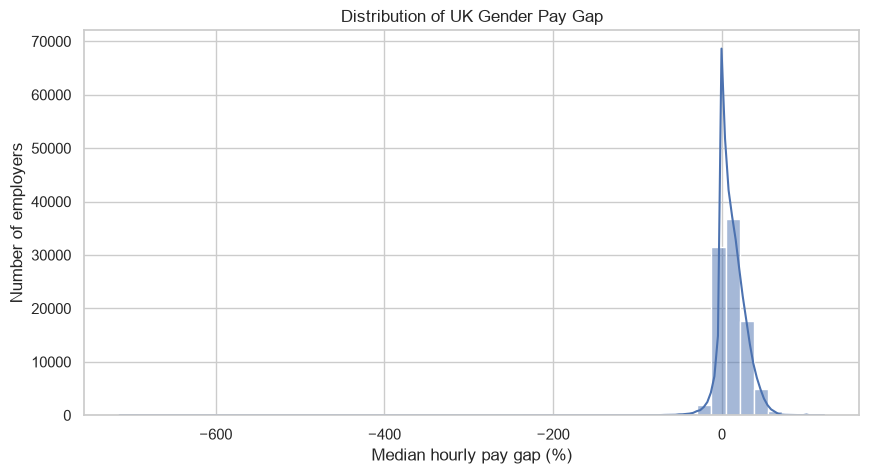

In [6]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data["DiffMedianHourlyPercent"].dropna(),
    bins=50,
    kde=True
)

plt.title("Distribution of UK Gender Pay Gap")
plt.xlabel("Median hourly pay gap (%)")
plt.ylabel("Number of employers")

plt.show()

In [9]:
import sys
from pathlib import Path

# Locate the project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "config.py").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

# Add project root to Python's search path
sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)
print("config.py exists:", (PROJECT_ROOT / "config.py").exists())

Project root: c:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project
config.py exists: True


In [17]:
from pathlib import Path
import sys

PROJECT_DIR = Path(
    r"C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project"
)

sys.path.insert(0, str(PROJECT_DIR))

print("Project directory:", PROJECT_DIR)
print("Directory exists:", PROJECT_DIR.exists())
print("Outputs exists:", (PROJECT_DIR / "outputs").exists())


for file in (PROJECT_DIR / "outputs").rglob("*.csv"):
    print(file)


Project directory: C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project
Directory exists: True
Outputs exists: True
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\yearly_gender_pay_gap_trend.csv
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\main\tables\ablation_results_2023.csv
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\main\tables\bootstrap_results_2024.csv
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\main\tables\classification_class_shares_2024.csv
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\main\tables\classification_results_2024.csv
C:\Users\HP\Downloads\predictive analysis project\predictive analysis project\gpg_project\outputs\main\tables\cleaned_data.csv
C:\Users\HP\Downloads\predic

In [18]:
panel = pd.read_csv(
    PROJECT_DIR / "outputs" / "main" / "tables" / "employer_year_panel.csv"
)

print("Panel loaded successfully!")
print("Shape:", panel.shape)

display(panel.head())

Panel loaded successfully!
Shape: (74777, 41)


,employer_name,employer_id,Address,PostCode,company_number,sic_codes,gap_mean,gap_median,bonus_gap_mean,bonus_gap_median,male_bonus_pct,female_bonus_pct,male_lower_q,female_lower_q,male_lowmid_q,female_lowmid_q,male_upmid_q,female_upmid_q,male_top_q,female_top_q,CompanyLinkToGPGInfo,ResponsiblePerson,employer_size,CurrentName,submitted_late,due_date,date_submitted,report_year,days_late,fem_gradient,employer_size_ord,sector,is_fashion,is_retail_other,is_unknown,next_year,gap_next,prev_year,gap_prev,change_prev,target_change
0,BLACKWELL UK LIMITED,10,"203-206 Piccadilly, London, England, W1J 9HD",W1J 9HD,00796591,"47610,\r\n47620",11.5,1.8,0.7,25.6,26.5,23.7,41.7,58.3,50.4,49.6,44.5,55.5,59.2,40.8,https://blackwells.co.uk/bookshop/editorial/ge...,Kate Stilborn (Customer Service and Operation...,250 to 499,BLACKWELL UK LIMITED,0,2018-04-05,2018-04-03 11:49:33,2017,0,-17.5,1.0,retail_other,0,1,0,2018.0,1.4,NaN,NaN,NaN,-0.4
1,BLACKWELL UK LIMITED,10,"203-206 Piccadilly, London, England, W1J 9HD",W1J 9HD,00796591,"47610,\r\n47620",12.8,1.4,41.3,0.0,8.2,2.7,36.5,63.5,50.5,49.5,50.9,49.1,57.0,43.0,https://blackwells.co.uk/bookshop/editorial/ge...,Kate Stilborn (Customer Service & Operations D...,250 to 499,BLACKWELL UK LIMITED,0,2019-04-05,2019-04-02 13:36:06,2018,0,-20.5,1.0,retail_other,0,1,0,2019.0,1.9,2017.0,1.8,-0.4,0.5
2,BLACKWELL UK LIMITED,10,"203-206 Piccadilly, London, England, W1J 9HD",W1J 9HD,00796591,"47610,\r\n47620",13.1,1.9,19.0,18.4,81.8,79.1,41.0,59.0,50.0,50.0,49.0,51.0,56.0,44.0,https://blackwells.co.uk/bookshop/editorial/ge...,Kathryn Stilborn (Customer Service & Operation...,250 to 499,BLACKWELL UK LIMITED,0,2020-04-05,2020-05-04 14:43:10,2019,29,-15.0,1.0,retail_other,0,1,0,2020.0,27.0,2018.0,1.4,0.5,25.1
3,BLACKWELL UK LIMITED,10,"203-206 Piccadilly, London, England, W1J 9HD",W1J 9HD,00796591,"47610,\r\n47620",19.3,27.0,23.9,0.0,3.6,2.2,56.0,44.0,53.0,47.0,56.0,44.0,56.0,44.0,https://blackwells.co.uk/bookshop/editorial/ge...,Kate Stilborn (Customer Service & Operations D...,250 to 499,BLACKWELL UK LIMITED,1,2021-10-06,2021-10-26 14:32:59,2020,20,0.0,1.0,retail_other,0,1,0,2021.0,13.0,2019.0,1.9,25.1,-14.0
4,BLACKWELL UK LIMITED,10,"203-206 Piccadilly, London, England, W1J 9HD",W1J 9HD,00796591,"47610,\r\n47620",18.3,13.0,-42.1,-37.7,6.3,2.7,57.0,43.0,50.0,50.0,52.0,48.0,52.0,48.0,https://blackwells.co.uk/bookshop/editorial/ge...,Kate Stilborn (Customer Service & Operations D...,Less than 250,BLACKWELL UK LIMITED,0,2022-04-05,2022-01-04 15:30:19,2021,0,5.0,0.0,retail_other,0,1,0,2022.0,1.9,2020.0,27.0,-14.0,-11.1


In [12]:
import config
import modelling
import analysis
import matplotlib.pyplot as plt
import seaborn as sns

print("All imports successful!")

All imports successful!


In [19]:
print("Columns:")
print(panel.columns.tolist())

print("\nMissing values:")
print(panel.isnull().sum().sort_values(ascending=False).head(10))

Columns:
['employer_name', 'employer_id', 'Address', 'PostCode', 'company_number', 'sic_codes', 'gap_mean', 'gap_median', 'bonus_gap_mean', 'bonus_gap_median', 'male_bonus_pct', 'female_bonus_pct', 'male_lower_q', 'female_lower_q', 'male_lowmid_q', 'female_lowmid_q', 'male_upmid_q', 'female_upmid_q', 'male_top_q', 'female_top_q', 'CompanyLinkToGPGInfo', 'ResponsiblePerson', 'employer_size', 'CurrentName', 'submitted_late', 'due_date', 'date_submitted', 'report_year', 'days_late', 'fem_gradient', 'employer_size_ord', 'sector', 'is_fashion', 'is_retail_other', 'is_unknown', 'next_year', 'gap_next', 'prev_year', 'gap_prev', 'change_prev', 'target_change']

Missing values:
CompanyLinkToGPGInfo    26814
gap_prev                16961
change_prev             16961
bonus_gap_median        15466
bonus_gap_mean          15465
prev_year               13676
ResponsiblePerson       13461
company_number          10278
sic_codes                5199
employer_size_ord         743
dtype: int64


In [20]:
data = panel.copy()

print("Data ready for visualisation:", data.shape)

Data ready for visualisation: (74777, 41)
